# Chung et al. 2017 — Breast Cancer (SmartSeq2)
## 01 · Preprocessing → malignant manifold

Load malignant cells, drop under-populated samples, overdispersed-gene selection, PCA, Harmony integration on `sample`, UMAP, island removal, sub-region identity (signatures + cell cycle), and the **Gate 1** call (sample-mixed AND continuous) read off the regenerated embedding.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Chung2017_Breast
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Chung2017_Breast | category: Breast


### Load malignant cells
SmartSeq2 TPM (loader log1p's the TPM). Malignant selected on the publication `cell_type`.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p TPM)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Chung2017_Breast
Done.
full atlas: (515, 57915)
malignant: (317, 57915) | samples: 12
expression: X max 12.90 (log1p TPM)


### Sample threshold — re-derived for SmartSeq2 scale (C1/C3/C4)
The anchor floor (>=100 cells/sample) was fitted on a dataset with thousands of malignant cells. Here the **largest** sample has 75 malignant cells, so a floor of 100 empties the dataset — the anchor constant is not portable. There is also no dominant spillover cliff (below), so the geometric-mean rule does not apply. We re-derive a scale-appropriate floor: **require >=10 malignant cells/sample** — the minimum for a stable per-sample Harmony centroid and to avoid singleton-dominated neighbourhoods on a plate-based dataset of a few hundred cells.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
ANCHOR_FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*ANCHOR_FLOOR)   # a real spillover cliff?
print('sorted per-sample malignant counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
print(f'anchor floor {ANCHOR_FLOOR} vs largest sample {int(vals[0])}: floor exceeds all samples -> not portable')
FLOOR = 10   # scale-appropriate: min cells for a stable per-sample batch centroid
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'FLOOR = {FLOOR} -> kept {len(keep)}/{len(n)} samples (dropped {list(n.index[n < FLOOR])}); '
      f'{adata.shape[0]} cells; min per-sample = {int(n[n>=FLOOR].min())}')

sorted per-sample malignant counts: {'BC05': np.int64(75), 'BC02': np.int64(53), 'BC04': np.int64(47), 'BC07': np.int64(26), 'BC07LN': np.int64(26), 'BC01': np.int64(20), 'BC03': np.int64(15), 'BC08': np.int64(15), 'BC11': np.int64(11), 'BC10': np.int64(11), 'BC03LN': np.int64(10), 'BC06': np.int64(8)}
gap ratios: ['75->53:1.42', '53->47:1.13', '47->26:1.81', '26->26:1.00', '26->20:1.30', '20->15:1.33', '15->15:1.00', '15->11:1.36', '11->11:1.00', '11->10:1.10', '10->8:1.25']
argmax gap 47->26 (ratio 1.81); top/second = 1.28; dominant cliff = False
anchor floor 100 vs largest sample 75: floor exceeds all samples -> not portable
FLOOR = 10 -> kept 11/12 samples (dropped ['BC06']); 309 cells; min per-sample = 10


### Genes → overdispersion → PCA

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance ratio[:12]:', np.round(vr[:12], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 401 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 401
PCA variance ratio[:12]: [0.1362, 0.0902, 0.0615, 0.0382, 0.0331, 0.0226, 0.0177, 0.0133, 0.0122, 0.0105, 0.0089, 0.0085]


### Harmony integration on `sample` — strength sweep
Per-neighbourhood same-sample fraction (k=30) measures batch mixing (random baseline ~ 1/n_samples). Sweep theta and pick the strength where mixing improves sharply then flattens.

In [6]:
from sklearn.neighbors import NearestNeighbors
def _same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('random baseline ~ %.3f' % (1.0/adata.obs['sample'].nunique()))
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(mixing improves sharply to theta=5 then flattens; theta=10 within noise of theta=5 --',
      'strongest integration for the SmartSeq2 patient batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

random baseline ~ 0.091
same-sample neighbour fraction | pre-Harmony 0.754 | sweep {2: 0.496, 5: 0.246, 10: 0.254}
selected theta = 10 (mixing improves sharply to theta=5 then flattens; theta=10 within noise of theta=5 -- strongest integration for the SmartSeq2 patient batch effect, without collapsing structure)


### Island removal
UMAP radius graph at 6x the median nearest-neighbour distance; keep the largest connected component.

In [7]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
if int((lab!=main).sum()) > 0:
    sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 0 cells in 0 detached islands


### Sub-region identity — biology before geometry
Leiden sub-clusters, cell-cycle phase, and a proliferation score per lobe: confirm the manifold is one low-cycling body (not a real second lineage, not a proliferation compartment confounding the signatures).

In [8]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
adata.obs['compartment'] = 'Body'
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('-> single low-cycling body; lobes share signature relationships (checked below). One trajectory object.')

lobe sizes: {'0': 179, '1': 130}
overall cycling fraction: 0.191
cycling fraction per lobe: {'0': 0.229, '1': 0.138}
proliferation score per lobe: {'0': -0.302, '1': -0.176}
-> single low-cycling body; lobes share signature relationships (checked below). One trajectory object.


### Module scores + house orientation
Score Gast/pSom/Crest (union control pool), graph-smooth for the developmental-origin axis, and store a rigid rotation of the UMAP (`X_umap_lin`, distances preserved -- NOT a re-embedding) with the Gast/pSom-high origin pole on the left, so 01-04 share one orientation.

In [9]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
origin_score = (S[:,0] + S[:,1]) - S[:,2]     # Gast+pSom-high / Crest-low = developmental origin
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('lobe smoothed module means (identity check):')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3))

xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot),-np.sin(-theta_rot)],[np.sin(-theta_rot),np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg, Gast/pSom-high origin on left -> X_umap_lin')

Gast: 75/81 genes present
pSom: 85/98 genes present
Crest: 99/104 genes present
raw module means: {'Gast': -0.2757, 'pSom': 0.1239, 'Crest': -0.0738}
lobe smoothed module means (identity check):
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      -0.311    0.091    -0.029
1      -0.245    0.159    -0.103
manifold aspect (max/min std): 1.42
house orientation: rigid rotation -59.8deg, Gast/pSom-high origin on left -> X_umap_lin


### Gate 1 — mixed AND continuous (read off the regenerated embedding)
iLISI (per-neighbourhood effective #samples) quantifies mixing; the island test quantifies continuity. The sample-coloured embedding (below) is the primary evidence.

In [10]:
def _ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component, no islands removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)')

iLISI median: pre-Harmony 3.81 -> post-Harmony(theta=10) 5.93 of 11 samples
11 samples share one continuous manifold (one connected component, no islands removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)


### Save processed.h5ad

In [11]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        keep_num = s.notna().sum() > 0 and conv.notna().sum() >= 0.9*s.notna().sum()
        adata.obs[col] = conv if keep_num else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (309, 24851)


### samples.pdf — sample-coloured manifold (Gate-1 evidence)
House style: (3.5,1.5) horizontal strip, size=30, house orientation (`X_umap_lin`).

saved samples.pdf | cells: 309


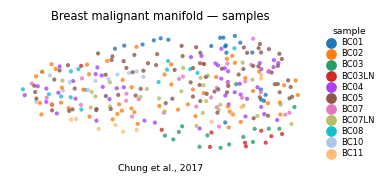

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Chung et al., 2017', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])